# 03. Results: the papers' DFO-TR, v1.3, v2.3 and SIRT-box

Budget: 1M function evaluations per run, 10 seeds per method and setting; SIRT-box: 50k iterations.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import dfoct
from dfoct import analysis as an

FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
R = an.load()
problems = {(s, a): dfoct.load_problem(p, s, a) for p, s, a in dfoct.SETTINGS}
pd.options.display.float_format = "{:.3g}".format

## Main table (1M FEs)

In [2]:
fin = an.finals(R["main"])
t = R["timing"].set_index(["method", "size", "alpha"]).us_per_fe
med_t = R["tuning"].groupby(["method", "size", "alpha"]).psnr.median()
cells = med_t[med_t.index.get_level_values(0).str.startswith("±")]
best_cell = {(s, a): cells.xs((s, a), level=(1, 2)).idxmax() for s, a in an.settings()}
rows = []
for s, a in an.settings():
    for m in ("DFO-TR (paper)", "v1.3", "v2.3"):
        sub = fin[(fin.method == m) & (fin["size"] == s) & (fin.alpha == a)]
        rows.append({"setting": an.label(s, a), "method": m, "PSNR (dB)": sub.psnr.median(), "SSIM": sub.ssim.median(),
                     "e1": sub.e1.median(), "pixels at 0 or 255": sub.on_bound.median(),
                     "seconds (one thread)": t[(m, s, a)] * fin.fes.max() / 1e6})
    sb = R["sirt"].set_index(["size", "alpha"]).loc[(s, a)]
    rows.append({"setting": an.label(s, a), "method": "SIRT-box", "PSNR (dB)": sb.psnr, "SSIM": sb.ssim, "e1": sb.e1,
                 "pixels at 0 or 255": sb.on_bound, "seconds (one thread)": sb.seconds})
main_table = pd.DataFrame(rows).set_index(["setting", "method"])
main_table.to_csv(FIGURES / "main_table.csv")
an.to_tex(main_table.drop(columns="e1"), FIGURES / "tab_main.tex")
main_table

PSNR (dB)  SSIM       e1  pixels at 0 or 255  \
setting         method                                                         
32² / 6 angles  DFO-TR (paper)       13.1 0.433 3.72e+03               0.748   
                v1.3                 13.2 0.441  3.8e+03               0.747   
                v2.3                 20.9 0.774      366               0.421   
                SIRT-box             22.7 0.846     1.24               0.444   
64² / 6 angles  DFO-TR (paper)       11.9 0.316 7.08e+05               0.815   
                v1.3                 11.8  0.31 6.64e+05               0.812   
                v2.3                 16.7 0.398 2.32e+06               0.303   
                SIRT-box               19 0.683     86.6               0.492   
32² / 32 angles DFO-TR (paper)       20.8 0.789 2.18e+05               0.565   
                v1.3                 20.8 0.801 2.11e+05               0.565   
                v2.3                 36.4 0.987 2.62e+03               0.441   
                SIRT-box             71.5     1    0.218               0.474   

                                seconds (one thread)  
setting         method                                
32² / 6 angles  DFO-TR (paper)                  45.2  
                v1.3                           0.163  
                v2.3                           0.908  
                SIRT-box                       0.772  
64² / 6 angles  DFO-TR (paper)                   108  
                v1.3                           0.518  
                v2.3                            4.84  
                SIRT-box                         3.1  
32² / 32 angles DFO-TR (paper)                  89.9  
                v1.3                            1.31  
                v2.3                            5.65  
                SIRT-box                        3.87

## v2.3 against the papers' DFO-TR and against v1.3 (1M FEs)

In [3]:
for other in ("DFO-TR (paper)", "v1.3"):
    for metric in ("psnr", "ssim"):
        display(an.compare(fin, "v2.3", other, metric).rename_axis(f"{metric.upper()}: v2.3 vs {other}"))
an.to_tex(an.compare(fin, "v2.3", "v1.3"), FIGURES / "tab_v2_3_vs_v1_3.tex", digits=3)
grid_best = pd.DataFrame({an.label(s, a): {
    "v2.3": med_t[("v2.3", s, a)], "best grid cell": best_cell[(s, a)], "its PSNR": med_t[(best_cell[(s, a)], s, a)]}
    for s, a in an.settings()}).T
an.to_tex(grid_best, FIGURES / "tab_grid_best.tex")
grid_best

,v2.3 median,DFO-TR (paper) median,v2.3 better (pairs),Mann-Whitney p
PSNR: v2.3 vs DFO-TR (paper),,,,
32² / 6 angles,20.9,13.1,100%,0.000183
64² / 6 angles,16.7,11.9,100%,0.000183
32² / 32 angles,36.4,20.8,100%,0.000183


,v2.3 median,DFO-TR (paper) median,v2.3 better (pairs),Mann-Whitney p
SSIM: v2.3 vs DFO-TR (paper),,,,
32² / 6 angles,0.774,0.433,100%,0.000183
64² / 6 angles,0.398,0.316,100%,0.000183
32² / 32 angles,0.987,0.789,100%,0.000183


,v2.3 median,v1.3 median,v2.3 better (pairs),Mann-Whitney p
PSNR: v2.3 vs v1.3,,,,
32² / 6 angles,20.9,13.2,100%,0.000183
64² / 6 angles,16.7,11.8,100%,0.000183
32² / 32 angles,36.4,20.8,100%,0.000183


,v2.3 median,v1.3 median,v2.3 better (pairs),Mann-Whitney p
SSIM: v2.3 vs v1.3,,,,
32² / 6 angles,0.774,0.441,100%,0.000183
64² / 6 angles,0.398,0.31,100%,0.000183
32² / 32 angles,0.987,0.801,100%,0.000183


,v2.3,best grid cell,its PSNR
32² / 6 angles,20.9,±0.05 Δ0.003,20.9
64² / 6 angles,16.7,±0.25 Δ0.001,17.3
32² / 32 angles,36.4,±0.1 Δ0.003,40.4


## Images and errors (median seed)

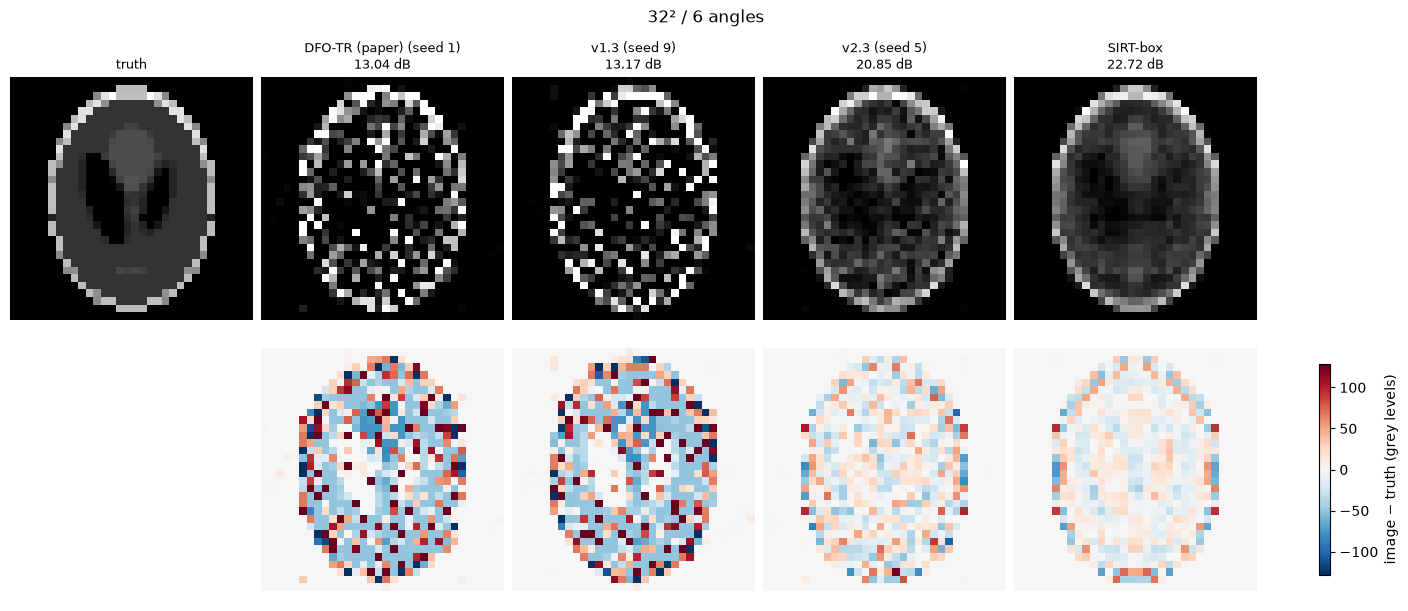

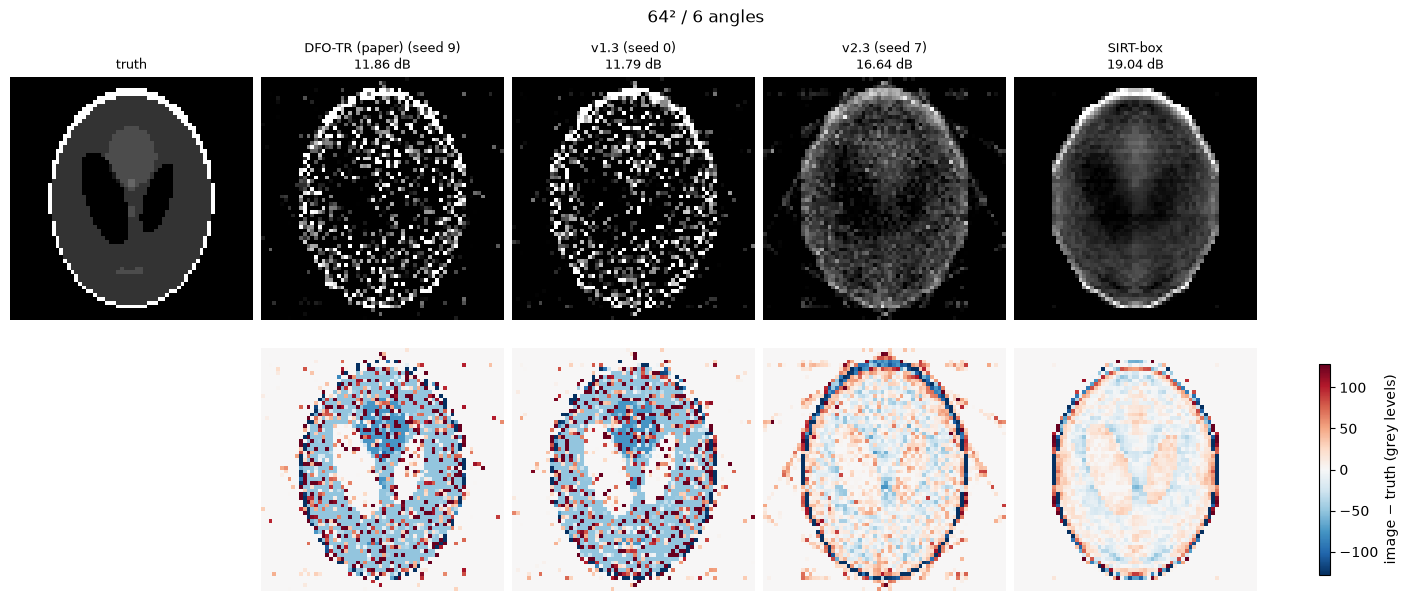

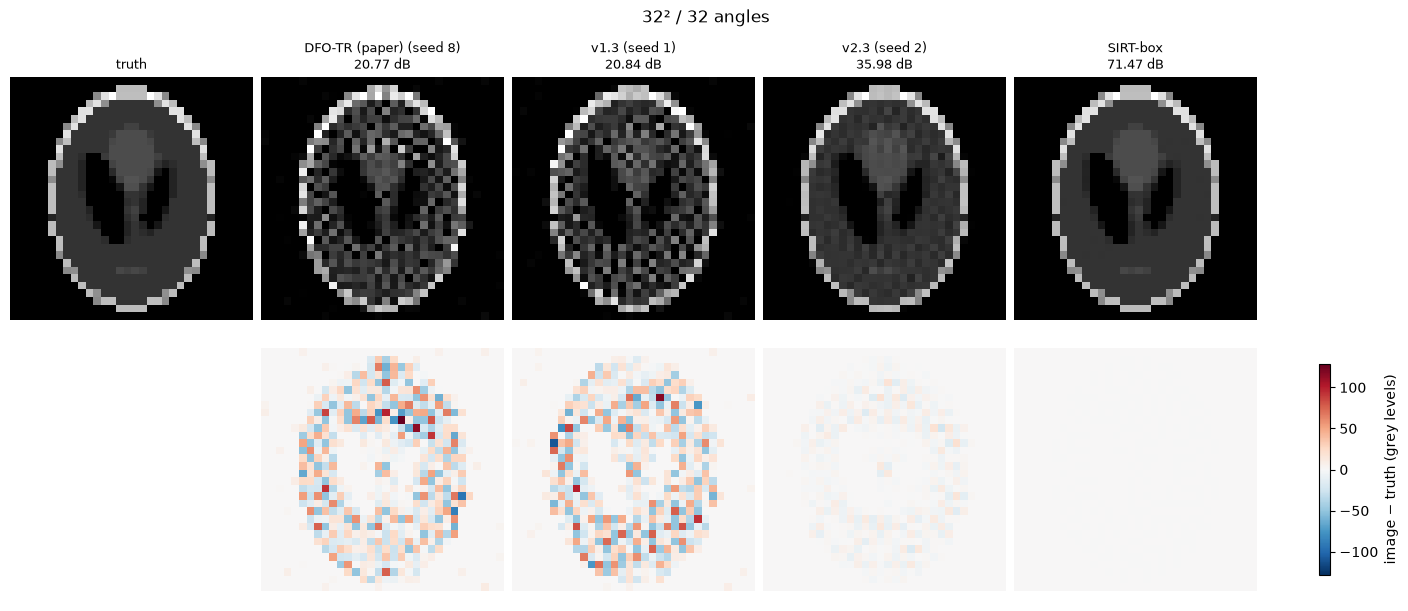

In [4]:
for s, a in an.settings():
    p = problems[(s, a)]
    cols = ["DFO-TR (paper)", "v1.3", "v2.3", "SIRT-box"]
    fig, axes = plt.subplots(2, 5, figsize=(14, 6), layout="constrained")
    an.show(axes[0, 0], p.phantom, s, "truth")
    axes[1, 0].axis("off")
    for k, m in enumerate(cols, 1):
        if m == "SIRT-box":
            x = R["sirt_images"][f"SIRT-box|{s}|{a}"]
            title = "SIRT-box"
        else:
            seed = an.median_seed(fin, m, s, a)
            x = R["images"][f"{m}|{s}|{a}|{seed}"]
            title = f"{m} (seed {seed})"
        an.show(axes[0, k], x, s, f"{title}\n{dfoct.score(p, x)['psnr']:.2f} dB")
        im = an.show_error(axes[1, k], x, p.phantom, s)
        axes[1, k].axis("off")
    fig.colorbar(im, ax=axes[1, :], shrink=0.8, label="image − truth (grey levels)")
    fig.suptitle(an.label(s, a))
    fig.savefig(FIGURES / f"images_{s}_{a}.pdf", bbox_inches="tight")

## Held-out images (1M FEs)

Images never used in development or tuning: phantom 5 on new seeds (100–109), phantom 1 (binary) and phantom 1 re-greyed to 64/192, and 12 LoDoPaB-CT validation slices (6 whole, 6 crops; seeds 100–104).

In [5]:
H = R["heldout"]
fin_h = H[(H.method != "SIRT-box") & (H.fes == H.fes.max())]
sirt_h = H[H.method == "SIRT-box"]
rows = {}
for name, key in an.HELDOUT_SETS.items():
    sub = an.heldout_set(fin_h, key)
    row = {}
    for s, a in an.settings():
        cell = sub[(sub["size"] == s) & (sub.alpha == a)].groupby("method").psnr.median()
        row[an.label(s, a)] = f"{cell['v1.3']:.1f} → {cell['v2.3']:.1f}".replace("inf", "∞")
    won, n = an.paired_wins(sub, "v2.3", "v1.3")
    row["v2.3 better (paired runs)"] = f"{won}/{n}"
    rows[name] = row
tab_h = pd.DataFrame(rows).T.rename_axis("held-out set (median PSNR, v1.3 → v2.3)")
display(tab_h)
an.to_tex(tab_h, FIGURES / "tab_heldout.tex")

,32² / 6 angles,64² / 6 angles,32² / 32 angles,v2.3 better (paired runs)
"held-out set (median PSNR, v1.3 → v2.3)",,,,
"Real CT, whole slices",9.9 → 25.8,9.5 → 24.5,13.4 → 33.0,90/90
"Real CT, crops",9.4 → 25.9,9.1 → 25.5,12.5 → 33.4,90/90
Phantom 1 re-greyed (64/192),9.5 → 18.8,8.9 → 18.3,12.7 → 25.0,30/30
Phantom 1 binary,∞ → 18.9,30.1 → 12.8,∞ → 20.8,0/30
"Phantom 5, new seeds",13.2 → 20.7,12.0 → 16.6,20.8 → 37.2,30/30


In [6]:
# the other numbers the text may need: SSIM, SIRT-box, the ±0.1 grid cell, and the 100k checkpoint
def medians(df, metric):
    out = {}
    for name, key in an.HELDOUT_SETS.items():
        sub = an.heldout_set(df, key)
        out[name] = sub.groupby(["method", "size", "alpha"])[metric].median()
    return pd.DataFrame(out).T

display(medians(fin_h, "ssim").round(2).rename_axis("SSIM at 1M FEs"))
display(medians(sirt_h, "psnr").round(1).rename_axis("SIRT-box PSNR (50k iterations)"))
display(medians(H[H.fes == 100_000], "psnr").round(1).rename_axis("PSNR at 100k FEs"))
for name, key in an.HELDOUT_SETS.items():
    sub = an.heldout_set(fin_h, key)
    won, n = an.paired_wins(sub, "±0.1 Δ0.003", "v2.3")
    print(f"±0.1 Δ0.003 better than v2.3 on {name}: {won}/{n} paired runs")

method                       v1.3           v2.3           ±0.1 Δ0.003       \
size                           32        64   32        64          32        
alpha                          6    32   6    6    32   6           6    32   
SSIM at 1M FEs                                                                
Real CT, whole slices        0.02 0.06 0.01 0.44 0.81 0.34        0.42 0.78   
Real CT, crops               0.01 0.04 0.01 0.38 0.77 0.34        0.38 0.74   
Phantom 1 re-greyed (64/192) 0.21 0.36 0.06  0.5 0.69 0.23        0.48  0.7   
Phantom 1 binary                1    1 0.93 0.66 0.71 0.14           1    1   
Phantom 5, new seeds         0.43 0.79 0.32 0.76 0.99 0.39        0.76 0.99   

method                             
size                           64  
alpha                          6   
SSIM at 1M FEs                     
Real CT, whole slices        0.31  
Real CT, crops               0.31  
Phantom 1 re-greyed (64/192) 0.21  
Phantom 1 binary             0.43  
Phantom 5, new seeds         0.48

method                         SIRT-box          
size                                 32        64
alpha                                6    32   6 
SIRT-box PSNR (50k iterations)                   
Real CT, whole slices              32.8   49 30.4
Real CT, crops                     34.5 53.5 33.1
Phantom 1 re-greyed (64/192)       22.3 33.8 22.2
Phantom 1 binary                    118  128  107
Phantom 5, new seeds               22.7 71.5   19

method                       v1.3           v2.3           ±0.1 Δ0.003       \
size                           32        64   32        64          32        
alpha                          6    32   6    6    32   6           6    32   
PSNR at 100k FEs                                                              
Real CT, whole slices         9.9 12.6  9.5 25.2 27.2   24          25 29.2   
Real CT, crops                9.4 11.8  9.1 25.9 29.1 25.5        25.8 31.1   
Phantom 1 re-greyed (64/192)  9.5   12  8.9   14   14 13.2        15.7 15.9   
Phantom 1 binary             72.2  inf 18.3  7.4  7.3  7.1         8.4  8.2   
Phantom 5, new seeds         12.9 18.8 11.7 14.5 14.7 13.6        15.6 16.2   

method                             
size                           64  
alpha                          6   
PSNR at 100k FEs                   
Real CT, whole slices        23.6  
Real CT, crops               24.9  
Phantom 1 re-greyed (64/192) 14.2  
Phantom 1 binary              7.6  
Phantom 5, new seeds         14.1

±0.1 Δ0.003 better than v2.3 on Real CT, whole slices: 3/90 paired runs
±0.1 Δ0.003 better than v2.3 on Real CT, crops: 6/90 paired runs
±0.1 Δ0.003 better than v2.3 on Phantom 1 re-greyed (64/192): 3/30 paired runs
±0.1 Δ0.003 better than v2.3 on Phantom 1 binary: 30/30 paired runs
±0.1 Δ0.003 better than v2.3 on Phantom 5, new seeds: 20/30 paired runs


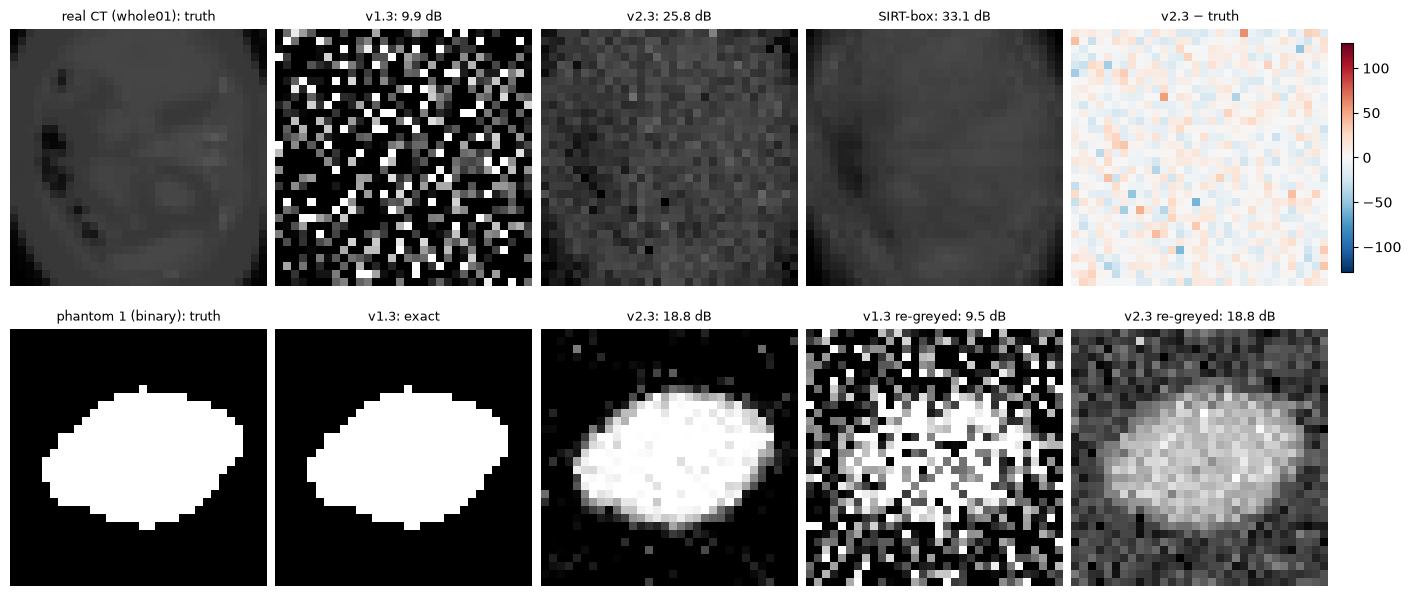

In [7]:
def pick(df, image, method, s, a):
    """The median-PSNR seed's final image, and its PSNR."""
    sub = df[(df.image == image) & (df.method == method)]
    seed = an.median_seed(sub, method, s, a)
    psnr = sub[(sub["size"] == s) & (sub.alpha == a) & (sub.seed == seed)].psnr.iloc[0]
    return R["heldout_images"][f"{image}|{method}|{s}|{a}|{seed}"], psnr

s, a = 32, 6
whole = fin_h[(fin_h.method == "v2.3") & fin_h.image.str.startswith("ct-whole") & (fin_h["size"] == s) & (fin_h.alpha == a)]
per_image = whole.groupby("image").psnr.median().sort_values()
ct = per_image.index[(len(per_image) - 1) // 2]  # the whole slice with the median v2.3 score
fig, axes = plt.subplots(2, 5, figsize=(14, 6), layout="constrained")
an.show(axes[0, 0], dfoct.load_image_problem(ct, s, a).phantom, s, f"real CT ({ct[3:]}): truth")
for k, m in enumerate(("v1.3", "v2.3"), 1):
    x, psnr = pick(fin_h, ct, m, s, a)
    an.show(axes[0, k], x, s, f"{m}: {psnr:.1f} dB")
xs = R["heldout_images"][f"{ct}|SIRT-box|{s}|{a}|-1"]
an.show(axes[0, 3], xs, s, f"SIRT-box: {sirt_h[(sirt_h.image == ct) & (sirt_h['size'] == s) & (sirt_h.alpha == a)].psnr.iloc[0]:.1f} dB")
x23, _ = pick(fin_h, ct, "v2.3", s, a)
im = an.show_error(axes[0, 4], x23, dfoct.load_image_problem(ct, s, a).phantom, s)
axes[0, 4].set_title("v2.3 − truth", fontsize=9); axes[0, 4].axis("off")
an.show(axes[1, 0], dfoct.load_image_problem("phantom1", s, a).phantom, s, "phantom 1 (binary): truth")
for k, (image, m) in enumerate((("phantom1", "v1.3"), ("phantom1", "v2.3"), ("phantom1-grey", "v1.3"), ("phantom1-grey", "v2.3")), 1):
    x, psnr = pick(fin_h, image, m, s, a)
    grey = " re-greyed" if image.endswith("grey") else ""
    an.show(axes[1, k], x, s, f"{m}{grey}: " + ("exact" if np.isinf(psnr) else f"{psnr:.1f} dB"))
fig.colorbar(im, ax=axes[0, 4], shrink=0.8)
fig.savefig(FIGURES / "heldout.pdf", bbox_inches="tight")
plt.show()

## PSNR against FEs and against time

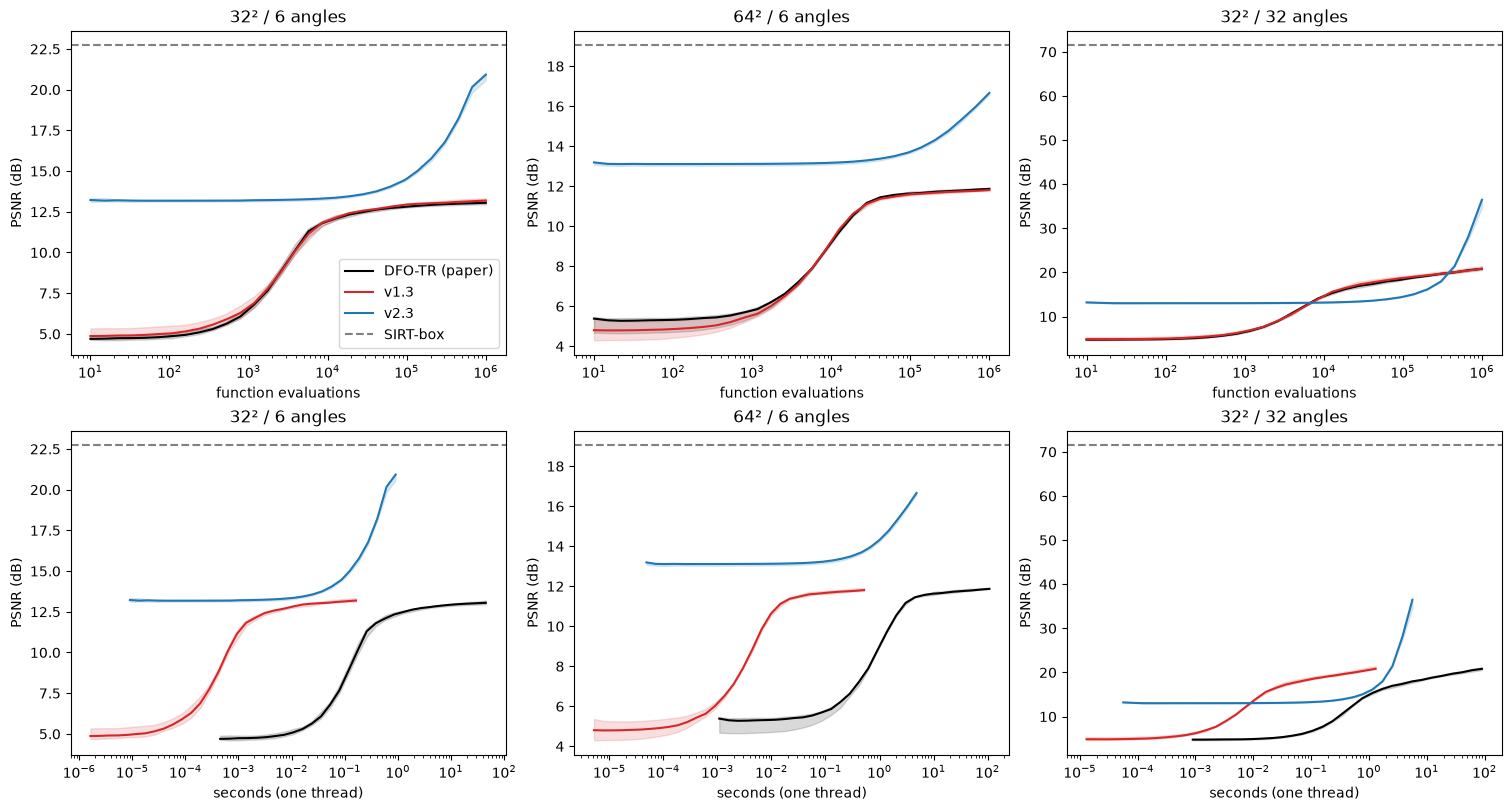

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout="constrained")
for k, (s, a) in enumerate(an.settings()):
    for m in ("DFO-TR (paper)", "v1.3", "v2.3"):
        sub = R["main"][(R["main"].method == m) & (R["main"]["size"] == s) & (R["main"].alpha == a)]
        q = sub.groupby("fes").psnr.quantile([0.25, 0.5, 0.75]).unstack()
        for row, xs in enumerate((q.index, q.index * t[(m, s, a)] / 1e6)):
            axes[row, k].plot(xs, q[0.5], color=an.COLORS[m], label=m)
            axes[row, k].fill_between(xs, q[0.25], q[0.75], color=an.COLORS[m], alpha=0.15)
    sb = R["sirt"].set_index(["size", "alpha"]).psnr[(s, a)]
    for row, xl in enumerate(("function evaluations", "seconds (one thread)")):
        axes[row, k].axhline(sb, color="grey", ls="--", label="SIRT-box")
        axes[row, k].set(xscale="log", xlabel=xl, ylabel="PSNR (dB)", title=an.label(s, a))
axes[0, 0].legend()
fig.savefig(FIGURES / "progress.pdf", bbox_inches="tight")